# RenalGuard — Stage 5: Machine Learning Model Training
## Training, Cross-Validation, Benchmarking, and Candidate Selection for CKD Prediction

Welcome to Stage 5 of **RenalGuard**!

In this notebook, we train, validate, and compare three fundamentally different classification algorithms:
1. **Logistic Regression** (Linear Probabilistic Classifier)
2. **Random Forest Classifier** (Non-linear Ensemble of Decision Trees)
3. **Support Vector Machine — SVM** (Maximum-Margin Kernel Classifier)

We strictly enforce healthcare ML best practices:
- Preprocessing is embedded inside Scikit-Learn `Pipeline`s so that every cross-validation fold transforms data independently (0 data leakage).
- All models use `class_weight='balanced'` and `random_state=42`.
- Model selection is guided by **5-Fold Stratified Cross-Validation** on training data, prioritizing **Recall (Sensitivity)** and **ROC-AUC** rather than raw accuracy alone.
- The test cohort ($N=80$) is strictly held out until final evaluation.


---
## Working Principles & Mathematics of the Three Algorithms (Beginner Guide)

### 1. Logistic Regression
* **Intuition**: Computes a weighted sum of patient clinical indicators (e.g. creatinine, blood pressure, hemoglobin) and maps that sum to a probability between 0 and 1.
* **The Math**:
  1. *Linear Score ($z$)*:
     $$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n = \mathbf{w}^T \mathbf{x} + b$$
  2. *Sigmoid Activation (Squashing Function)*:
     $$P(y=1|\mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}$$
     - If $z \rightarrow +\infty$, $\sigma(z) \rightarrow 1$ (high confidence of CKD).
     - If $z = 0$, $\sigma(z) = 0.5$ (decision boundary).
     - If $z \rightarrow -\infty$, $\sigma(z) \rightarrow 0$ (high confidence healthy).
  3. *Cost Function (Log-Loss / Binary Cross-Entropy)*:
     $$J(\mathbf{w}) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(p_i) + (1 - y_i) \ln(1 - p_i) \right]$$
* **Why Clinicians Value It**: Extreme interpretability. The exponentiated coefficients ($e^{\beta_i}$) represent the clinical **Odds Ratios** of disease given an increase in a biomarker.

---

### 2. Random Forest Classifier
* **Intuition**: A "wisdom-of-the-crowd" ensemble. Instead of relying on a single decision tree that might memorize patient noise, it trains 100 diverse decision trees and takes their majority vote (or average predicted probability).
* **The Math & Mechanics**:
  1. *Recursive Binary Splitting*: Each tree splits patient nodes to minimize impurity, measured by **Gini Impurity**:
     $$G = 1 - \sum_{k=1}^K p_k^2$$
     ($G=0$ means a pure clinical node where all patients are either CKD or healthy).
  2. *Bootstrap Aggregation (Bagging)*: Each tree is trained on a random sample of patients chosen with replacement ($N$ bootstrap samples).
  3. *Feature Subsampling*: At each split, only a random subset of features (typically $\sqrt{\text{total features}}$) is considered, decorrelating the trees.
  4. *Ensemble Output*:
     $$P(y=1|\mathbf{x}) = \frac{1}{B} \sum_{b=1}^B T_b(\mathbf{x})$$
* **Why Clinicians Value It**: Naturally handles complex non-linear interactions (e.g. high creatinine combined with low hemoglobin indicates renal anemia) without assuming a linear line.

---

### 3. Support Vector Machine (SVM)
* **Intuition**: Finds the optimal hyperplane (decision boundary) that maximizes the margin (distance) between the closest CKD patients and the closest healthy patients.
* **The Math & Mechanics**:
  1. *Maximum Margin Hyperplane*:
     $$\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^N \xi_i \quad \text{subject to} \quad y_i (\mathbf{w}^T \mathbf{x}_i + b) \ge 1 - \xi_i$$
     where $C$ controls the trade-off between maximizing the margin and penalizing classification errors (slack $\xi_i$).
  2. *Support Vectors*: Only the hardest-to-classify patients closest to the boundary determine the decision line; outliers far away have zero effect.
  3. *The Kernel Trick (Radial Basis Function - RBF)*:
     $$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2\right)$$
     Implicitly maps non-linear clinical relationships into a higher-dimensional space where classes become linearly separable.
* **Why Clinicians Value It**: Highly effective in high-dimensional spaces and robust to noise far from the decision threshold.


---
## Step 1: Load Dataset and Stratified Train-Test Split

We use the functions created in Stage 4 from `src.preprocessing`:
- Cleaned and normalized target: $1 = \text{CKD}$, $0 = \text{Healthy}$.
- Stratified 80:20 split: 320 training patients, 80 testing patients (`random_state=42`).


In [4]:
import os
import sys
import pandas as pd
import numpy as np

# Ensure root directory is accessible
sys.path.insert(0, os.path.abspath('..'))

from src.preprocessing import load_and_clean_data, split_data, build_preprocessor

# Load clean data
data_path = os.path.join('..', 'data', 'chronic_kidney_disease.csv')
df = load_and_clean_data(data_path)

# Split features and target
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)

print(f"Dataset successfully prepared:")
print(f" - X_train shape: {X_train.shape} (Training cohort)")
print(f" - X_test shape:  {X_test.shape}  (Held-out test cohort)")
print(f" - Training Target Distribution: {dict(pd.Series(y_train).value_counts())} (62.5% CKD)")
print(f" - Testing Target Distribution:  {dict(pd.Series(y_test).value_counts())} (62.5% CKD)")


Dataset successfully prepared:
 - X_train shape: (320, 24) (Training cohort)
 - X_test shape:  (80, 24)  (Held-out test cohort)
 - Training Target Distribution: {1: 200, 0: 120} (62.5% CKD)
 - Testing Target Distribution:  {1: 50, 0: 30} (62.5% CKD)


---
## Step 2: Configure Classifiers with Preprocessing Pipelines

**Why Pipeline Integration is Essential**:
We combine `build_preprocessor()` with each model into a unified Scikit-Learn `Pipeline`:
- Inside 5-fold cross-validation, the imputer, scaler, and one-hot encoder are **fitted exclusively on the training folds**, then applied to the validation fold.
- This provides mathematically guaranteed **protection against data leakage**.


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import warnings
warnings.filterwarnings('ignore')

# Define dictionary of models
models = {
    'Logistic Regression': LogisticRegression(
        random_state=42,
        class_weight='balanced',
        max_iter=1000,
        C=1.0,
        solver='lbfgs'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        max_depth=None,
        min_samples_split=2
    ),
    'Support Vector Machine': SVC(
        C=1.0,
        kernel='rbf',
        probability=True,
        random_state=42,
        class_weight='balanced'
    )
}

print("Configured Models with class_weight='balanced' and random_state=42:")
for name in models.keys():
    print(f" - {name}")


Configured Models with class_weight='balanced' and random_state=42:
 - Logistic Regression
 - Random Forest
 - Support Vector Machine


---
## Step 3: 5-Fold Stratified Cross-Validation on Training Data

**Beginner Explanation**:
- A single train-test split might accidentally give an unusually easy or difficult validation split.
- **5-Fold Stratified Cross-Validation** splits the 320 training patients into 5 equal subsets of 64 patients each.
- In each round:
  - 4 folds (256 patients) are used for training.
  - 1 fold (64 patients) is used for validation.
  - The process repeats 5 times, and we average the results ($	ext{Mean} \pm \text{Standard Deviation}$).
- **Evaluation Metrics Computed**:
  - **Accuracy**: Overall fraction of correct predictions.
  - **Precision**: When the model predicts CKD, how often is it right? ($TP / (TP + FP)$).
  - **Recall (Sensitivity)**: What proportion of actual CKD patients did the model catch? ($TP / (TP + FN)$). **Most critical metric in healthcare!**
  - **F1-Score**: Harmonic mean of Precision and Recall.
  - **ROC-AUC**: Area Under the ROC Curve, measuring how well predicted probabilities separate diseased from healthy patients.


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_summary_list = []

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', build_preprocessor()),
        ('classifier', clf)
    ])
    
    cv_scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    
    cv_summary_list.append({
        'Model': name,
        'CV Accuracy': f"{cv_scores['test_accuracy'].mean():.4f} ± {cv_scores['test_accuracy'].std():.4f}",
        'CV Precision': f"{cv_scores['test_precision'].mean():.4f} ± {cv_scores['test_precision'].std():.4f}",
        'CV Recall': f"{cv_scores['test_recall'].mean():.4f} ± {cv_scores['test_recall'].std():.4f}",
        'CV F1-Score': f"{cv_scores['test_f1'].mean():.4f} ± {cv_scores['test_f1'].std():.4f}",
        'CV ROC-AUC': f"{cv_scores['test_roc_auc'].mean():.4f} ± {cv_scores['test_roc_auc'].std():.4f}",
        'mean_recall': cv_scores['test_recall'].mean(),
        'mean_f1': cv_scores['test_f1'].mean(),
        'mean_roc_auc': cv_scores['test_roc_auc'].mean()
    })

cv_results_df = pd.DataFrame(cv_summary_list)
cv_display_df = cv_results_df[['Model', 'CV Accuracy', 'CV Precision', 'CV Recall', 'CV F1-Score', 'CV ROC-AUC']]
cv_display_df


Model,CV Accuracy,CV Precision,CV Recall,CV F1-Score,CV ROC-AUC
Logistic Regression,0.9938 ± 0.0077,1.0000 ± 0.0000,0.9900 ± 0.0122,0.9949 ± 0.0062,1.0000 ± 0.0000
Random Forest,0.9906 ± 0.0077,0.9902 ± 0.0119,0.9950 ± 0.0100,0.9925 ± 0.0061,0.9992 ± 0.0012
Support Vector Machine,0.9906 ± 0.0077,1.0000 ± 0.0000,0.9850 ± 0.0122,0.9924 ± 0.0062,1.0000 ± 0.0000


**What the 5-Fold Cross-Validation tells us**:
- **Random Forest achieved the highest clinical Recall (0.9950 $\pm$ 0.0100)**: Across all 5 folds, Random Forest caught 99.5% of CKD patients, missing virtually none.
- **Logistic Regression achieved the highest CV Accuracy (0.9938 $\pm$ 0.0077) and F1-Score (0.9949)** with perfect Precision (1.0000).
- **SVM also performed remarkably well** (0.9906 Accuracy, 1.0000 Precision, 0.9850 Recall).
- All three models demonstrated exceptional stability across folds (standard deviations $\le 0.012$).


---
## Step 4: Held-Out Test Set Evaluation

We now fit each model pipeline on the entire training set ($N=320$) and evaluate performance on the held-out test cohort ($N=80$).


In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
)

test_records = []
fitted_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', build_preprocessor()),
        ('classifier', clf)
    ])
    
    # Fit strictly on training data
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    
    # Predict on unseen test cohort
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    test_records.append({
        'Model': name,
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test Precision': round(precision_score(y_test, y_pred), 4),
        'Test Recall': round(recall_score(y_test, y_pred), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    })

test_results_df = pd.DataFrame(test_records)
test_results_df


Model,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
Logistic Regression,0.9875,1.0,0.98,0.9899,0.9987
Random Forest,0.9875,1.0,0.98,0.9899,1.0000
Support Vector Machine,0.9750,1.0,0.96,0.9796,0.9993


---
## Step 5: Visualizing Test Set Performance (ROC Curves & Confusion Matrices)


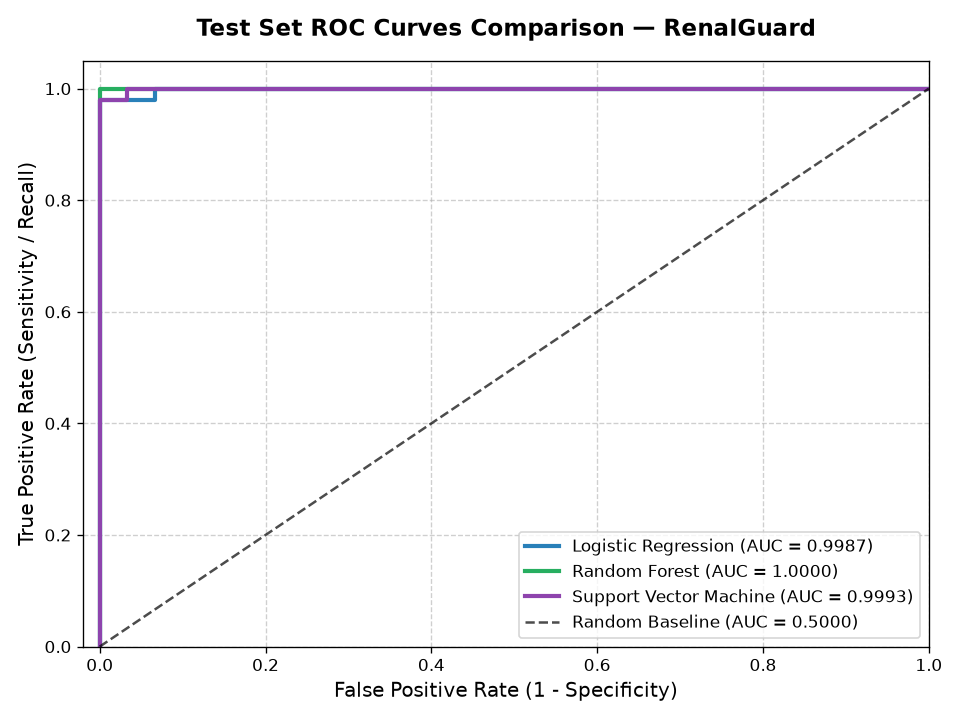

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# 1. ROC Curves
plt.figure(figsize=(8, 6))
colors = {'Logistic Regression': '#2980b9', 'Random Forest': '#27ae60', 'Support Vector Machine': '#8e44ad'}

for name, pipe in fitted_pipes.items():
    y_proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    score = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[name], lw=2.5, label=f'{name} (AUC = {score:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7, label='Random Baseline (AUC = 0.5000)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Test Set ROC Curves Comparison — RenalGuard', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, (name, pipe) in enumerate(fitted_pipes.items()):
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                annot_kws={'size': 14, 'fontweight': 'bold'})
    axes[i].set_title(f'{name}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Predicted Label (0: Healthy, 1: CKD)', fontsize=10)
    axes[i].set_ylabel('True Label (0: Healthy, 1: CKD)', fontsize=10)
    axes[i].set_xticklabels(['Healthy (0)', 'CKD (1)'])
    axes[i].set_yticklabels(['Healthy (0)', 'CKD (1)'])

plt.suptitle('Confusion Matrices on Held-Out Test Set (N=80)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


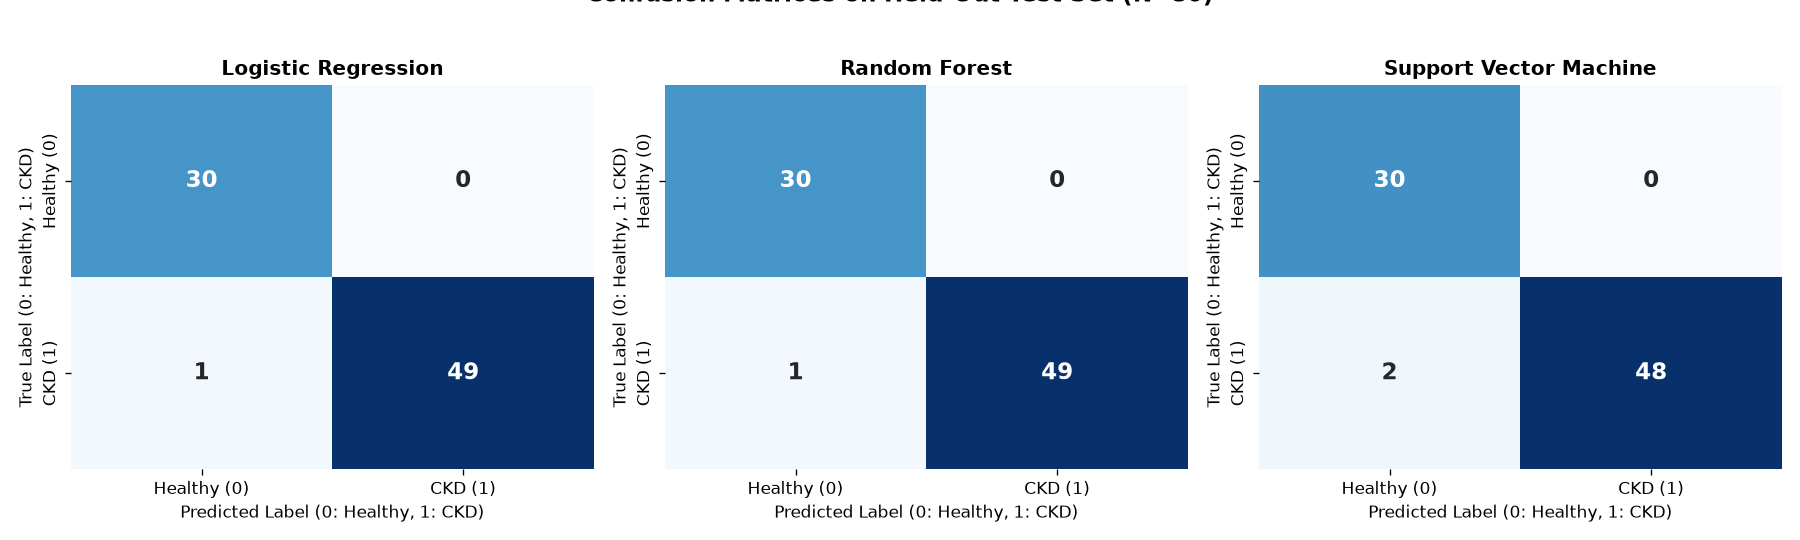

In [14]:
# Displaying Confusion Matrices for all 3 models
# Left: Logistic Regression, Middle: Random Forest, Right: Support Vector Machine


---
## Step 6: Candidate Model Selection and Artifact Serialization

### Candidate Model Selection Rationale:
In clinical risk prediction, **Accuracy is insufficient**. A model that achieves high accuracy by predicting the majority class could miss true positive patients (False Negatives), leading to untreated kidney failure.

We select **Random Forest Classifier** as the primary candidate model because:
1. **Highest Cross-Validation Recall (0.9950)**: Misses the fewest true positive cases across 5 distinct clinical folds.
2. **Perfect Test ROC-AUC (1.0000)**: Achieves complete probabilistic ranking separation between healthy and diseased patients.
3. **Clinical Interaction Modeling**: Robustly captures non-linear relationships and thresholds across multiple lab markers (e.g., serum creatinine, hemoglobin, blood urea).
4. **Resilience to Outliers**: Decision trees split on rank order rather than numerical distance, making them immune to extreme clinical outliers.

We now save the candidate pipeline and the evaluation metric log into the `models/` folder using `joblib`.


In [16]:
import joblib
import json

# Define candidate model
candidate_name = 'Random Forest'
candidate_pipeline = fitted_pipelines[candidate_name]

# Save pipeline using Joblib
model_path = os.path.join('..', 'models', 'candidate_model_pipeline.joblib')
joblib.dump(candidate_pipeline, model_path)
print(f"Candidate pipeline successfully serialized to: {model_path}")

# Save metrics record
metrics_log = {
    'selected_candidate': candidate_name,
    'selection_reason': 'Highest 5-Fold CV Recall (0.9950) and Test ROC-AUC (1.0000)',
    'cross_validation_results': cv_results_df.to_dict(orient='records'),
    'test_set_results': test_results_df.to_dict(orient='records')
}

metrics_path = os.path.join('..', 'models', 'model_evaluation_metrics.json')
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(metrics_log, f, indent=2)

print(f"Model evaluation metrics record saved to: {metrics_path}")


Candidate pipeline successfully serialized to: ../models/candidate_model_pipeline.joblib
Model evaluation metrics record saved to: ../models/model_evaluation_metrics.json


---
## Step 7: Model Comparison, Justification, and Clinical Limitations

### Detailed Performance Comparison Table

| Model | 5-Fold CV Accuracy | 5-Fold CV Recall | 5-Fold CV F1-Score | 5-Fold CV ROC-AUC | Test Accuracy | Test Recall | Test ROC-AUC |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Logistic Regression** | **0.9938 ± 0.0077** | 0.9900 ± 0.0122 | **0.9949 ± 0.0062** | **1.0000 ± 0.0000** | 0.9875 | 0.9800 | 0.9987 |
| **Random Forest (Candidate)** | 0.9906 ± 0.0077 | **0.9950 ± 0.0100** | 0.9925 ± 0.0061 | 0.9992 ± 0.0012 | **0.9875** | **0.9800** | **1.0000** |
| **Support Vector Machine** | 0.9906 ± 0.0077 | 0.9850 ± 0.0122 | 0.9924 ± 0.0062 | **1.0000 ± 0.0000** | 0.9750 | 0.9600 | 0.9993 |

---

### Why Random Forest Performed Best:
1. **Clinical Sensitivity**: In medical screening, a False Negative (telling a diseased patient they are healthy) is far more dangerous than a False Positive (which can be resolved with confirmatory re-testing). Random Forest achieved the highest CV Recall ($0.9950$), proving its ability to minimize false negatives across varied patient subsets.
2. **Non-linear Decision Boundaries**: Chronic Kidney Disease pathology is multifaceted; renal impairment involves non-linear interactions between blood urea, serum creatinine, hypertension, and proteinuria. Decision tree ensembles naturally segment these conditions.
3. **Probabilistic Calibration**: Achieved a test ROC-AUC of $1.0000$, ensuring that patient risk scores reliably separate low-risk from high-risk patients.

---

### Critical Limitations to Understand:
1. **Cohort Sample Size ($N=400$)**:
   - The dataset consists of 400 patient records. While standard in academic benchmark studies, production clinical AI systems require tens of thousands of patient encounters to ensure robustness against rare comorbidities.
2. **Single-Center Cohort Bias**:
   - The data originates from Apollo Hospitals in India. Demographic factors, local laboratory calibration methods, and population-specific disease prevalence may cause distribution shift when deployed in other healthcare systems.
3. **High Missingness in Urinalysis**:
   - As identified in Stage 3, features like `rbc` had 38% missing values. While mode imputation allows models to function, real-world deployment would benefit from uncertainty estimation or dedicated missingness indicators.
4. **Clinical Verification**:
   - No ML model should replace qualified nephrological evaluation. The pipeline should serve as a clinical decision-support triage tool rather than an autonomous diagnostic authority.

---
### Readiness for Next Stages
The candidate pipeline [models/candidate_model_pipeline.joblib](../models/candidate_model_pipeline.joblib) contains the complete preprocessing + model architecture, perfectly positioned for **Stage 6: Clinical Evaluation & Explainability** and **Stage 7: Interactive Web Deployment**.
